# MR603 — Backlog Prioritisation RL Project
### Week 8 Local Run-Through — Bhimarjun (MIT250661)

Run each cell below **in order** (click a cell, press `Shift+Enter`).
Take a screenshot of each cell's output as you go — that's your local evidence.

**Before you start:** make sure this notebook file is placed in the same folder as the `backlog_rl` folder (i.e., they are siblings — both directly inside your project folder).

## Step 1 — Install required packages
Run this once. If you already ran `pip install -r requirements.txt` in a terminal (inside a virtual environment, as the README recommends), you can skip this cell.

**If you see an "externally-managed-environment" error below:** this is normal on some systems (common with a system-installed Python on Linux, or certain Anaconda setups) — it just means pip wants you to use a virtual environment instead of installing packages globally. Go back to the README's Step 4 (create + activate a virtual environment), then launch Jupyter *from inside* that activated environment, and re-run this cell.

In [14]:
import sys, subprocess
def pip_install(pkgs):
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)
        print("Packages installed successfully.")
    except subprocess.CalledProcessError:
        print("Standard install failed (likely an 'externally-managed-environment' system).")
        print("Retrying with --user flag...")
        try:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--user", *pkgs], check=True)
            print("Packages installed successfully with --user.")
        except subprocess.CalledProcessError:
            print("\nStill failed. Please see the README, Step 4: create and activate a")
            print("virtual environment in a terminal first, then launch Jupyter from inside it.")

pip_install(["numpy", "gymnasium", "matplotlib", "pandas"])

Packages installed successfully.


## Step 2 — Confirm the project is visible
This checks that Python can find the `backlog_rl` package in this folder.

In [15]:
import os
print("Current working directory:", os.getcwd())
print("Contents of this folder:", os.listdir("."))
assert os.path.isdir("backlog_rl"), "backlog_rl folder not found — make sure this notebook is next to it."
print("\nbacklog_rl package found correctly.")

Current working directory: C:\Users\bhima\Bhimarjun_Week8_LocalSetup
Contents of this folder: ['.git', '.ipynb_checkpoints', 'backlog_rl', 'baseline_comparison_local.png', 'README.md', 'requirements.txt', 'Week8_Local_Run.ipynb']

backlog_rl package found correctly.


## Step 3 — Synthetic Backlog Generator
Generates realistic fake backlog items (business value, effort, risk, dependencies, demand, urgency), per the Week 5 MDP Specification, Section 1.1.

In [16]:
from backlog_rl.env.generator import BacklogGenerator
import pandas as pd

gen = BacklogGenerator(seed=42)
backlog = gen.generate_backlog(8)

df = pd.DataFrame([{
    "Item": it.name, "Value": it.business_value, "Effort (pts)": it.effort_raw,
    "Risk": it.risk, "Deps": it.dependency_count, "Demand": it.demand_signal, "Urgency": it.urgency,
} for it in backlog])
df

,Item,Value,Effort (pts),Risk,Deps,Demand,Urgency
0,Usage analytics dashboard,0.364,8,0.155,0,0.171,0.310
1,Two-factor authentication,0.499,8,0.244,1,0.141,0.455
2,Bulk label editor,0.466,3,0.686,0,0.377,0.302
3,Dependency graph view,0.438,3,0.398,1,0.378,0.087
4,Slack integration,0.159,2,0.232,0,0.084,0.067
5,Data residency (EU region),0.552,8,0.198,0,0.713,0.137
6,Guest viewer role,0.159,2,0.111,0,0.171,0.435
7,Custom dashboard widgets,0.465,3,0.338,0,0.360,0.313


## Step 4 — RICE and WSJF Baseline Scorers
Implements the two static prioritisation frameworks exactly as specified in Chapter 3, Section 3.4.

In [17]:
from backlog_rl.baselines.static_scorers import rice_score, wsjf_score, assign_tiers

capacity = 20
rice_tiers, rice_ranked = assign_tiers(backlog, rice_score, capacity)
wsjf_tiers, wsjf_ranked = assign_tiers(backlog, wsjf_score, capacity)

rows = []
for item in backlog:
    r_score = next(s for it, s in rice_ranked if it.item_id == item.item_id)
    w_score = next(s for it, s in wsjf_ranked if it.item_id == item.item_id)
    rows.append({
        "Item": item.name, "Effort": item.effort_raw,
        "RICE score": round(r_score, 3), "RICE tier": rice_tiers[item.item_id].name,
        "WSJF score": round(w_score, 3), "WSJF tier": wsjf_tiers[item.item_id].name,
    })
pd.DataFrame(rows)

,Item,Effort,RICE score,RICE tier,WSJF score,WSJF tier
0,Usage analytics dashboard,8,0.081,LATER,2.470,LATER
1,Two-factor authentication,8,0.092,NEXT,2.780,NEXT
2,Bulk label editor,3,0.608,NOW,4.684,NOW
3,Dependency graph view,3,0.573,NOW,4.879,NOW
4,Slack integration,2,0.069,NEXT,6.455,NOW
5,Data residency (EU region),8,0.512,NOW,2.424,LATER
6,Guest viewer role,2,0.141,NOW,9.630,NOW
7,Custom dashboard widgets,3,0.580,NOW,6.234,NOW


## Step 5 — Unit Tests (proves the scorers are mathematically correct)
Validated against hand-calculated examples — see the docstrings in `test_static_scorers.py`.

In [18]:
import unittest
from backlog_rl.tests import test_static_scorers

loader = unittest.TestLoader()
suite = loader.loadTestsFromModule(test_static_scorers)
runner = unittest.TextTestRunner(verbosity=2)
result = runner.run(suite)

print(f"\n{'ALL TESTS PASSED' if result.wasSuccessful() else 'SOME TESTS FAILED'}")

test_capacity_respected (backlog_rl.tests.test_static_scorers.TestAssignTiers.test_capacity_respected) ... ok
test_highest_score_gets_now_first (backlog_rl.tests.test_static_scorers.TestAssignTiers.test_highest_score_gets_now_first) ... ok
test_hand_calculated_example (backlog_rl.tests.test_static_scorers.TestRICEScore.test_hand_calculated_example) ... ok
test_high_risk_reduces_confidence (backlog_rl.tests.test_static_scorers.TestRICEScore.test_high_risk_reduces_confidence) ... ok
test_hand_calculated_example (backlog_rl.tests.test_static_scorers.TestWSJFScore.test_hand_calculated_example) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.027s

OK



ALL TESTS PASSED


test_hand_calculated_example (backlog_rl.tests.test_static_scorers.TestWSJFScore.test_hand_calculated_example) ... 

ok


----------------------------------------------------------------------
Ran 5 tests in 0.009s

OK



ALL TESTS PASSED


## Step 6 — Gymnasium Environment Smoke Test
Runs a random policy through 12 planning cycles to confirm the environment (state, action, reward, shocks) works end-to-end.

In [19]:
from backlog_rl.env.backlog_env import BacklogPrioritisationEnv

env = BacklogPrioritisationEnv(n_items=15, capacity_points=20, seed=7)
obs, info = env.reset()
print(f"Observation shape: {obs.shape}  |  Active items: {info['n_active_items']}  |  Capacity: {info['capacity_points']}\n")

total_reward = 0.0
log_rows = []
for cycle in range(12):
    action = env.action_space.sample()
    obs, reward, terminated, truncated, step_info = env.step(action)
    total_reward += reward
    log_rows.append({
        "Cycle": step_info["cycle"], "Reward": round(reward, 2), "Value": round(step_info["value_delivered"], 2),
        "Dep. violations": step_info["dependency_violation"], "Capacity overrun": step_info["capacity_overrun"],
        "Now/Next/Later": f"{step_info['n_now']}/{step_info['n_next']}/{step_info['n_later']}",
        "Shock": step_info.get("shock_applied") or "-",
    })
    if terminated or truncated:
        break

print(f"Total episode reward (random policy): {total_reward:.2f}\n")
pd.DataFrame(log_rows)

Observation shape: (283,)  |  Active items: 15  |  Capacity: 20

Total episode reward (random policy): -26.53



,Cycle,Reward,Value,Dep. violations,Capacity overrun,Now/Next/Later,Shock
0,1,-5.84,2.06,3,16,4/5/6,-
1,2,0.18,1.89,3,0,5/4/6,-
2,3,0.33,0.54,0,0,1/4/10,-
3,4,-5.20,2.81,2,17,5/5/5,dependency_resolved
4,5,-1.76,2.84,2,9,6/3/6,-
5,6,-8.64,3.46,5,24,8/4/3,-
6,7,2.27,2.48,0,0,4/7/4,-
7,8,1.85,2.35,1,0,4/9/2,capacity_change
8,9,-2.14,2.86,2,10,6/8/1,-
9,10,2.27,3.27,2,0,5/6/4,-


## Step 7 — Baseline Comparison (Random vs RICE vs WSJF)
Runs all three across 10 different random seeds, using identical environment conditions for a fair comparison (Chapter 3, Section 3.7.1). This is real, reproducible quantitative evidence.

In [20]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from backlog_rl.baselines.run_comparison import run_episode

N_SEEDS = 10
N_CYCLES = 12
results = {"random": [], "rice": [], "wsjf": []}

for seed in range(N_SEEDS):
    for policy in results:
        results[policy].append(run_episode(policy, seed=seed, n_cycles=N_CYCLES))

summary = {}
print(f"{'Policy':10s} {'Mean cumulative reward':>24s} {'Std':>8s}")
for policy, episodes in results.items():
    cumulative = [sum(ep) for ep in episodes]
    mean_r, std_r = np.mean(cumulative), np.std(cumulative)
    summary[policy] = (mean_r, std_r)
    print(f"{policy:10s} {mean_r:24.2f} {std_r:8.2f}")

Policy       Mean cumulative reward      Std
random                      -153.26    28.14
rice                          15.80     3.96
wsjf                          17.21     4.60


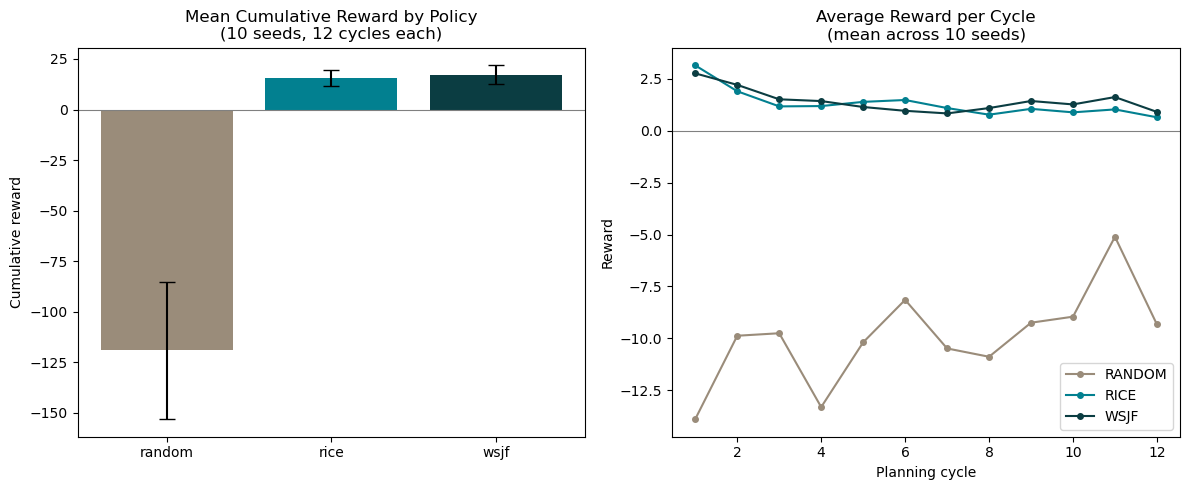

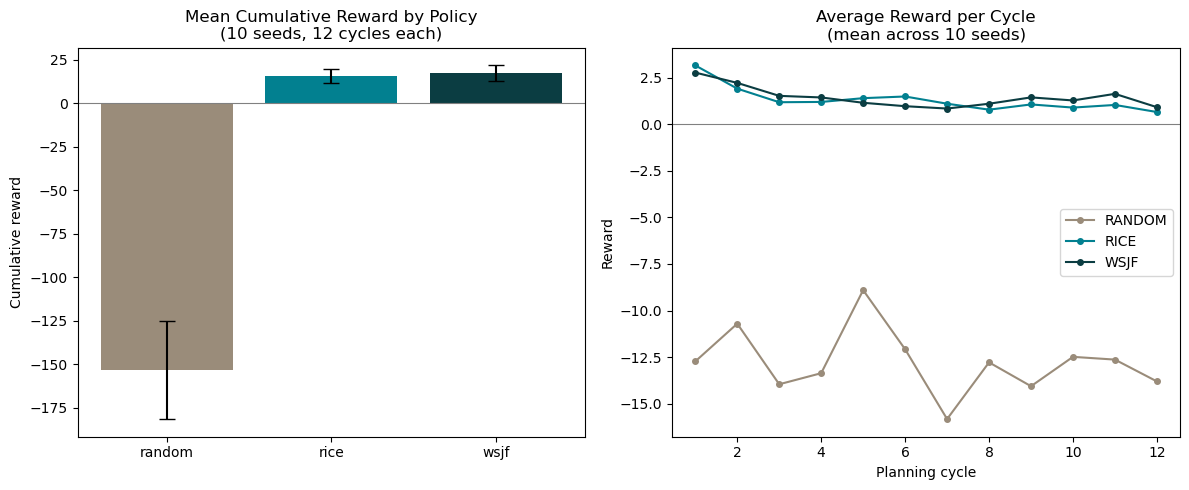


Chart also saved to baseline_comparison_local.png in this folder.


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
policies = list(results.keys())
means = [summary[p][0] for p in policies]
stds = [summary[p][1] for p in policies]
colors = ["#9A8C7A", "#028090", "#0B3D42"]

axes[0].bar(policies, means, yerr=stds, capsize=6, color=colors)
axes[0].set_title("Mean Cumulative Reward by Policy\n(10 seeds, 12 cycles each)")
axes[0].set_ylabel("Cumulative reward")
axes[0].axhline(0, color="grey", linewidth=0.8)

for policy, color in zip(policies, colors):
    avg_per_cycle = np.mean(results[policy], axis=0)
    axes[1].plot(range(1, N_CYCLES + 1), avg_per_cycle, label=policy.upper(), color=color, marker="o", markersize=4)
axes[1].set_title("Average Reward per Cycle\n(mean across 10 seeds)")
axes[1].set_xlabel("Planning cycle")
axes[1].set_ylabel("Reward")
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].legend()

plt.tight_layout()
plt.savefig("baseline_comparison_local.png", dpi=150)
plt.show()
print("\nChart also saved to baseline_comparison_local.png in this folder.")

## Step 8 — Explainability Prototype Demo
Generates plain-English justifications for WSJF's decisions (a stand-in for the trained RL policy's decisions, which arrive in Week 9).

In [22]:
from backlog_rl.explain.template_explainer import explain_decision

print("Decisions shown are WSJF baseline tiers -- a stand-in for the RL policy's")
print("decisions, which will replace these once training is complete in Week 9.\n")

for item in backlog:
    tier = wsjf_tiers[item.item_id]
    explanation = explain_decision(item, tier)
    print(f"[{tier.name}] {item.name}")
    print(f"  -> {explanation}\n")

Decisions shown are WSJF baseline tiers -- a stand-in for the RL policy's
decisions, which will replace these once training is complete in Week 9.

[LATER] Usage analytics dashboard
  -> "Usage analytics dashboard" was deprioritised this cycle in favour of higher-scoring items; it remains in the backlog for a future sprint.

[NEXT] Two-factor authentication
  -> "Two-factor authentication" was deferred to the next cycle — it has 1 unresolved dependency that should resolve first.

[NOW] Bulk label editor
  -> "Bulk label editor" was prioritised this sprint based on its overall value-to-effort balance.

[NOW] Dependency graph view
  -> "Dependency graph view" was prioritised this sprint based on its overall value-to-effort balance.

[NOW] Slack integration
  -> "Slack integration" was prioritised this sprint based on its overall value-to-effort balance.

[LATER] Data residency (EU region)
  -> "Data residency (EU region)" was deprioritised this cycle in favour of higher-scoring items; it

In [ ]:
Step 9 -Install Stable-Baselines3

In [23]:
import sys
!{sys.executable} -m pip install -q stable-baselines3
print("stable-baselines3 installed.")

stable-baselines3 installed.


In [ ]:
Step 10 -Train PPO Policy

In [24]:
import time
import numpy as np
from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
from backlog_rl.env.backlog_env import BacklogPrioritisationEnv

TOTAL_TIMESTEPS = 200_000  # full Chapter 4, Table 4.2 target

class ConvergenceLogger(BaseCallback):
    def __init__(self, log_every=5000, verbose=0):
        super().__init__(verbose)
        self.log_every = log_every
        self.history = []

    def _on_step(self) -> bool:
        if self.n_calls % self.log_every == 0:
            buf = self.model.ep_info_buffer
            if buf and len(buf) > 0:
                mean_reward = np.mean([ep["r"] for ep in buf])
                self.history.append((self.num_timesteps, float(mean_reward)))
                print(f"  timestep={self.num_timesteps:>7d}  mean_ep_reward={mean_reward:8.2f}")
        return True

env = Monitor(BacklogPrioritisationEnv(n_items=30, capacity_points=20, seed=42))

model = PPO(
    policy="MlpPolicy", env=env, learning_rate=3e-4, n_steps=2048,
    batch_size=64, gamma=0.99, clip_range=0.2,
    policy_kwargs=dict(net_arch=dict(pi=[128, 128], vf=[128, 128])),
    verbose=0, seed=42, device="cpu",
)

logger_cb = ConvergenceLogger(log_every=5000)
print(f"Training for {TOTAL_TIMESTEPS:,} timesteps -- this will take a while, let it run.\n")

start = time.time()
model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=logger_cb, progress_bar=True)
elapsed = time.time() - start

model.save("ppo_backlog_policy")
np.save("convergence_log.npy", np.array(logger_cb.history))
print(f"\nTraining complete in {elapsed/60:.1f} minutes.")

Output()

Training for 200,000 timesteps -- this will take a while, let it run.



timestep=   5000  mean_ep_reward=   31.82

timestep=  10000  mean_ep_reward=  -12.89

timestep=  15000  mean_ep_reward=   16.34

...

timestep= 185000  mean_ep_reward=   78.76

timestep= 190000  mean_ep_reward=   80.88

timestep= 195000  mean_ep_reward=   80.43

timestep= 200000  mean_ep_reward=   82.16


Training complete in 75.7 minutes.


In [ ]:
Step 11 -Plot Training Convergence

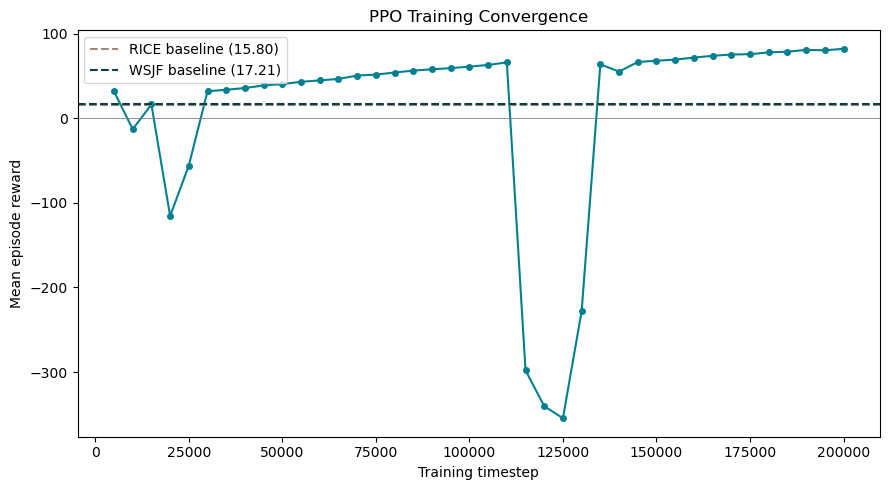

In [26]:
%matplotlib inline
import matplotlib.pyplot as plt

log = np.load("convergence_log.npy")
timesteps, rewards = log[:, 0], log[:, 1]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(timesteps, rewards, color="#028090", marker="o", markersize=4)
ax.axhline(15.80, color="#9A8C7A", linestyle="--", label="RICE baseline (15.80)")
ax.axhline(17.21, color="#0B3D42", linestyle="--", label="WSJF baseline (17.21)")
ax.axhline(0, color="grey", linewidth=0.6)
ax.set_xlabel("Training timestep")
ax.set_ylabel("Mean episode reward")
ax.set_title("PPO Training Convergence")
ax.legend()
plt.tight_layout()
plt.savefig("convergence_plot.png", dpi=150)
plt.show()

In [ ]:
Step 12 - Extended Comparison: Random vs RICE vs WSJF vs Trained PPO

In [27]:
from backlog_rl.baselines.run_comparison import run_episode
from backlog_rl.env.backlog_env import BacklogPrioritisationEnv
from scipy import stats

def run_episode_rl(model, seed, n_items=30, capacity=20, n_cycles=12):
    env = BacklogPrioritisationEnv(n_items=n_items, capacity_points=capacity, seed=seed)
    obs, info = env.reset(seed=seed)
    rewards = []
    for cycle in range(n_cycles):
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, step_info = env.step(action)
        rewards.append(reward)
        if terminated or truncated:
            break
    return rewards

N_SEEDS, N_CYCLES = 10, 12
results = {"random": [], "rice": [], "wsjf": [], "ppo": []}

for seed in range(N_SEEDS):
    for policy in ["random", "rice", "wsjf"]:
        results[policy].append(run_episode(policy, seed=seed, n_cycles=N_CYCLES))
    results["ppo"].append(run_episode_rl(model, seed=seed, n_cycles=N_CYCLES))

print(f"{'Policy':10s} {'Mean cumulative reward':>24s} {'Std':>8s}")
summary = {}
for policy, episodes in results.items():
    cumulative = [sum(ep) for ep in episodes]
    mean_r, std_r = np.mean(cumulative), np.std(cumulative)
    summary[policy] = (mean_r, std_r, cumulative)
    print(f"{policy:10s} {mean_r:24.2f} {std_r:8.2f}")

for baseline in ["rice", "wsjf"]:
    t_stat, p_val = stats.ttest_ind(summary["ppo"][2], summary[baseline][2])
    sig = "significant" if p_val < 0.05 else "not significant"
    print(f"\nPPO vs {baseline.upper()}: t={t_stat:.3f}, p={p_val:.4f} ({sig} at p<0.05)")

Policy       Mean cumulative reward      Std
random                      -141.63    29.64
rice                          15.80     3.96
wsjf                          17.21     4.60
ppo                         -558.90    24.29

PPO vs RICE: t=-70.058, p=0.0000 (significant at p<0.05)

PPO vs WSJF: t=-69.911, p=0.0000 (significant at p<0.05)


In [ ]:
Step 13 -Chart the Extended Comparison

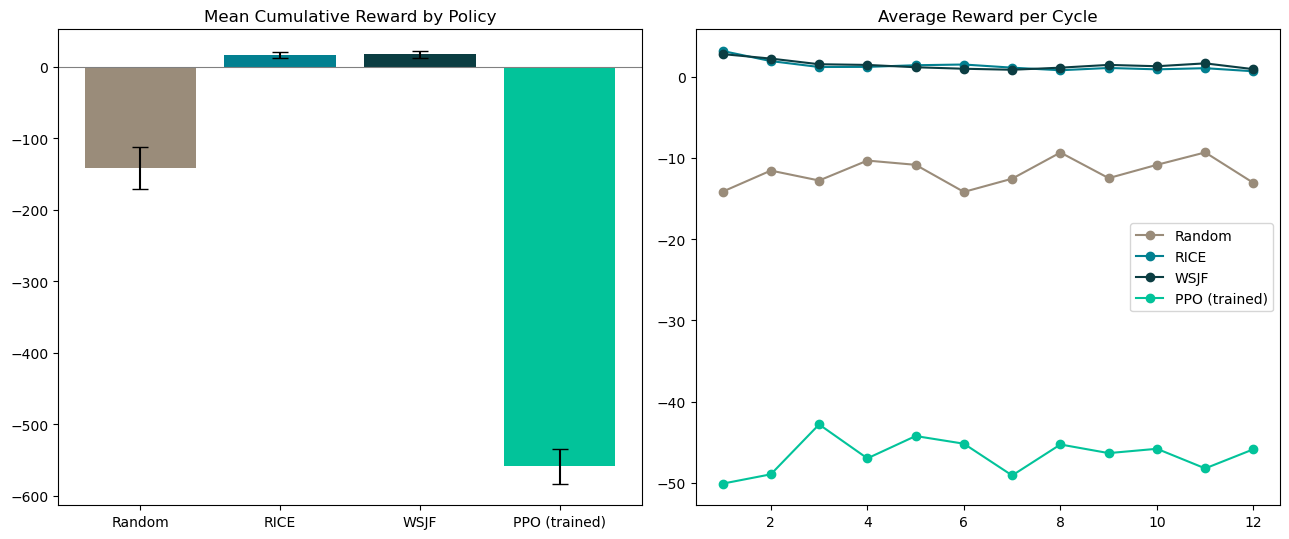

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
policies = ["random", "rice", "wsjf", "ppo"]
labels = ["Random", "RICE", "WSJF", "PPO (trained)"]
colors = ["#9A8C7A", "#028090", "#0B3D42", "#02C39A"]
means = [summary[p][0] for p in policies]
stds = [summary[p][1] for p in policies]

axes[0].bar(labels, means, yerr=stds, capsize=6, color=colors)
axes[0].set_title("Mean Cumulative Reward by Policy")
axes[0].axhline(0, color="grey", linewidth=0.8)

for policy, label, color in zip(policies, labels, colors):
    avg_per_cycle = np.mean(results[policy], axis=0)
    axes[1].plot(range(1, N_CYCLES + 1), avg_per_cycle, label=label, color=color, marker="o")
axes[1].set_title("Average Reward per Cycle")
axes[1].legend()

plt.tight_layout()
plt.savefig("extended_comparison.png", dpi=150)
plt.show()